# Problema de inventario.

## Descripción del Problema.

Considere un producto en una tienda. Debemos construir una estrategia para maximizar las ganancias.

## Descripción del Modelo.

Para construir nuestro modelo. Vamos a definir las variables elementales.

* $x_t$ es la cantidad del producto disponible en la etapa $t$.
* $\xi_t$ es la cantidad de producto solicitada en la etapa $t$.
* $a_t$ es la cantidad de prodcuto solicitada en la etapa $t$.

Notemos que dada la cantidad inicial $x_0$ en la etapa cero. En la siguiente etapa, despues de solicitar $a_1$ productos, habremos necesitado $\xi_1$ productos. Entonces la cantidad de producto en la siguiente etapa sería 
$$
    x_1 = x_0 + a_0 - \xi_1.
$$
Sin embargo, puede darse el caso que $\xi_1>x_0+a_0$, entonces nos quedaremos con la parte positiva. En general, la cantidad de producto en la etapa $t + 1$ esta dado por 
$$
    x_{t+1} = (x_t + a_t - \xi_{t+1})^{+},(\cdot)^{+}=\max(\cdot, 0)
$$

In [3]:
import numpy as np

def state(x, a, e):
    y = np.max([x+a-e, 0])
    return y

## Función de Costo

A lo largo de la libreta iremos revisando diferentes funciones de ganancia en función de los aditamientos que vayamos definiendo.

### Ganancia simplificada.

La ganancia simplificada consiste en calcular ganancia comparando la ganancia bruta menos los costos. Sea $V$ el precio de venta y $C$ el costo de solicitar el producto, entonces 

$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t, R_0 = 0
$$

In [ ]:
def sr(x,a,e, v,c):
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    return reward


### Ganancia sincera.

Definimos la ganancia sincera la ganancia simplificada pero agregando una penalización si la demanda llega a ser mayor al producto disponible. En general, podmeos definirla con una penalización constante $\eta$
$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t - \eta I_{\xi_{t+1}>x_t+a_t}.
$$

Pero, en caso de conocer la información, puede consideraese proporcional al producto no vendido por carencia
$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t - \eta \max\{\xi_{t+1}-x_t-a_t, 0\}.
$$


In [ ]:
def pure_reward(x,a,e,v,c,eta):
    # No observable
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    pen = 1 if e > x + a else 0
    return reward - eta * pen

# Miercoles 4 NO CLASE
# Jueves 4 a 6 (Virtual)
# Sabado 7 NO CLASE (Actividad)

def pure_reward_obs(x, a, e, v, c, eta):
    # observable
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    pen = eta * np.max([e > x + a, 0])
    return reward - pen


### Demanda

Por lo general la demanda es desconocida. Pero para esta libreta estara dada


(array([6.2000e+01, 2.1370e+03, 1.1532e+04, 1.2275e+04, 1.2052e+04,
        1.3723e+04, 1.0445e+04, 9.2880e+03, 9.2890e+03, 6.2100e+03,
        4.6620e+03, 3.9100e+03, 1.9360e+03, 1.3180e+03, 6.8700e+02,
        3.0300e+02, 1.0700e+02, 5.4000e+01, 9.0000e+00, 1.0000e+00]),
 array([  1.  ,   6.35,  11.7 ,  17.05,  22.4 ,  27.75,  33.1 ,  38.45,
         43.8 ,  49.15,  54.5 ,  59.85,  65.2 ,  70.55,  75.9 ,  81.25,
         86.6 ,  91.95,  97.3 , 102.65, 108.  ]),
 <BarContainer object of 20 artists>)

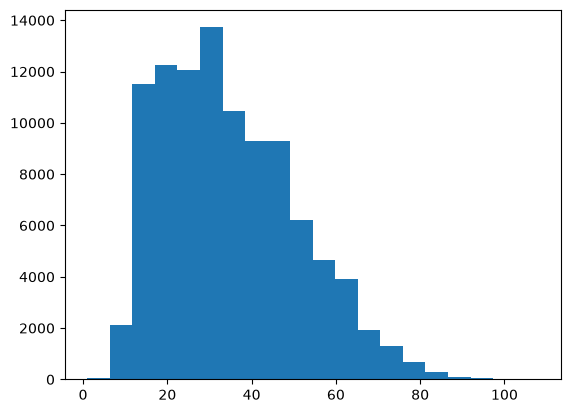

In [13]:
import matplotlib.pyplot as plt

def demmand():
    y = np.random.poisson(lam=10) + np.random.randint(1,10) * np.random.binomial(10, 0.5)
    return y

demmand_sample = [demmand() for _ in range(100_000)]

plt.hist(demmand_sample, bins=20)

